# 📈 Notebook 3 — Model Evaluation & Analysis
## AuthentiQ – AI Text Detection

This notebook loads the trained models from `../models/` and performs comprehensive evaluation:
- ROC Curve & Precision-Recall Curve
- Confusion Matrix with calibrated heatmap
- Per-source breakdown (how well does the model detect each AI model?)
- Error analysis (hardest examples)
- Sentence-level heat attribution
- Final performance card

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
import json
import re
import warnings
from pathlib import Path
from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, roc_curve, precision_recall_curve,
    average_precision_score
)

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor':'#0F1117','axes.facecolor':'#1A1D27','axes.edgecolor':'#2D3047',
    'axes.labelcolor':'#E2E8F0','xtick.color':'#94A3B8','ytick.color':'#94A3B8',
    'text.color':'#E2E8F0','grid.color':'#2D3047','grid.linestyle':'--','grid.alpha':0.4,
    'figure.dpi':120,
})
HUMAN_COLOR='#38BDF8'; AI_COLOR='#F472B6'; ACCENT='#A78BFA'; SUCCESS='#4ADE80'; WARN='#FB923C'
MODELS_DIR = Path('../models')
print('✅ Libraries loaded')

✅ Libraries loaded


## 1. Load Models & Recreate Validation Set

In [2]:
# Load saved artifacts
tfidf_char = joblib.load(MODELS_DIR / 'tfidf_char.pkl')
tfidf_word = joblib.load(MODELS_DIR / 'tfidf_word.pkl')
sgd_clf    = joblib.load(MODELS_DIR / 'sgd_classifier.pkl')
lgb_model  = joblib.load(MODELS_DIR / 'lgb_classifier.pkl')

with open(MODELS_DIR / 'model_meta.json') as f:
    meta = json.load(f)

print('✅ Models loaded')
print(json.dumps(meta, indent=2))

✅ Models loaded
{
  "model_version": "authentiq-v1.0",
  "train_samples": 38137,
  "val_samples": 6731,
  "char_features": 150391,
  "word_features": 300000,
  "ling_features": 12,
  "sgd_auc": 0.8894,
  "lgb_auc": 0.9996,
  "ensemble_auc": 0.997,
  "ensemble_acc": 0.9941,
  "ensemble_f1": 0.9923,
  "optimal_threshold": 0.5,
  "sgd_weight": 0.4708,
  "lgb_weight": 0.5292,
  "dataset": "train_v2_drcat_02.csv",
  "label_map": {
    "0": "Human",
    "1": "AI-Generated"
  }
}


In [3]:
def preprocess_text(text):
    text = str(text).strip()
    text = re.sub(r'\r\n|\r', '\n', text)
    text = re.sub(r'[ \t]{2,}', ' ', text)
    return text.lower()

def linguistic_features(texts):
    rows = []
    for text in texts:
        words = text.split()
        sents = [s.strip() for s in re.split(r'[.!?]+', text) if s.strip()]
        sl    = [len(s.split()) for s in sents]
        rows.append([
            len(text), len(words), len(sents),
            len(set(words))/max(len(words),1),
            np.std(sl) if len(sl)>1 else 0, np.mean(sl) if sl else 0,
            text.count(',')/max(len(words),1), text.count('!')/max(len(words),1),
            text.count('\n\n')+1,
            text.count('furthermore')+text.count('additionally'),
            text.count('moreover')+text.count('delve'),
            sum(1 for w in words if w.isupper() and len(w)>1)/max(len(words),1),
        ])
    return np.array(rows, dtype=np.float32)

# Load & split exactly the same way as training
df = pd.read_csv('../../../dataset/train_v2_drcat_02.csv')
df['text_clean'] = df['text'].apply(preprocess_text)

X, y = df['text_clean'].values, df['label'].values
_, X_val_raw, _, y_val, _, idx_val = train_test_split(
    X, y, df.index, test_size=0.15, random_state=42, stratify=y
)
df_val = df.loc[idx_val].copy()

# Build val features
X_val_char = tfidf_char.transform(X_val_raw)
X_val_word = tfidf_word.transform(X_val_raw)
X_val_ling = linguistic_features(X_val_raw)
X_val_all  = hstack([X_val_char, X_val_word, csr_matrix(X_val_ling)])

# Ensemble probabilities
sgd_probs = sgd_clf.predict_proba(X_val_all)[:, 1]
lgb_probs = lgb_model.predict_proba(X_val_all)[:, 1]
w_sgd, w_lgb = meta['sgd_weight'], meta['lgb_weight']
ens_probs = w_sgd*sgd_probs + w_lgb*lgb_probs

THRESHOLD = meta['optimal_threshold']
ens_preds = (ens_probs >= THRESHOLD).astype(int)
print(f'✅ Val set ready: {len(y_val):,} samples | Threshold: {THRESHOLD}')

✅ Val set ready: 6,731 samples | Threshold: 0.5


## 2. ROC & Precision-Recall Curves

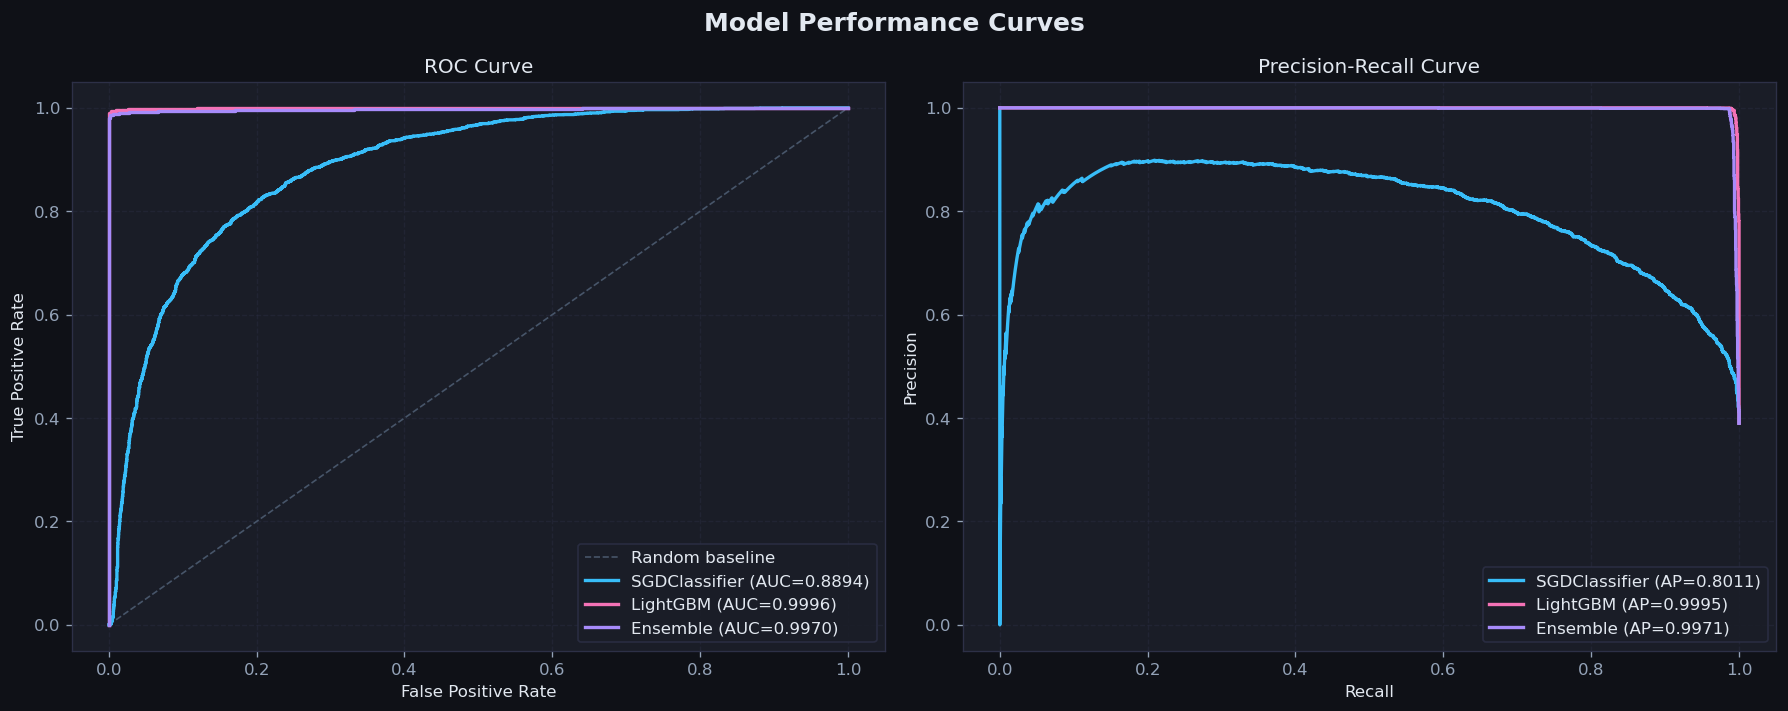

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Model Performance Curves', fontsize=15, fontweight='bold', color='#E2E8F0')

models_data = [
    ('SGDClassifier', sgd_probs, HUMAN_COLOR),
    ('LightGBM',      lgb_probs, AI_COLOR),
    ('Ensemble',      ens_probs, ACCENT),
]

# ROC Curve
ax = axes[0]
ax.plot([0,1],[0,1],'--',color='#475569',lw=1,label='Random baseline')
for name, probs, color in models_data:
    fpr, tpr, _ = roc_curve(y_val, probs)
    auc = roc_auc_score(y_val, probs)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC={auc:.4f})')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve', color='#E2E8F0'); ax.legend(facecolor='#1A1D27',edgecolor='#2D3047'); ax.grid(True)

# Precision-Recall Curve
ax = axes[1]
for name, probs, color in models_data:
    prec, rec, _ = precision_recall_curve(y_val, probs)
    ap = average_precision_score(y_val, probs)
    ax.plot(rec, prec, color=color, lw=2, label=f'{name} (AP={ap:.4f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve', color='#E2E8F0'); ax.legend(facecolor='#1A1D27',edgecolor='#2D3047'); ax.grid(True)

plt.tight_layout()
plt.savefig('../models/eval_roc_pr.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 3. Confusion Matrix

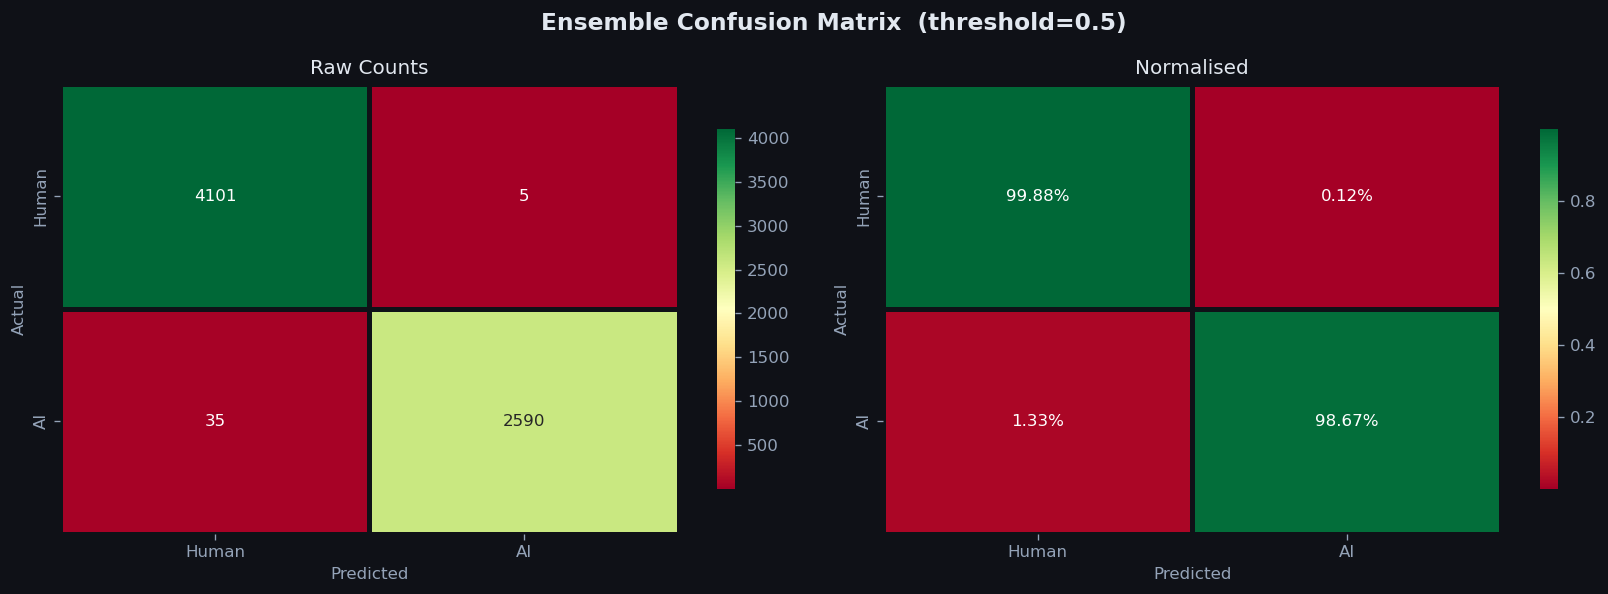


Classification Report:
              precision    recall  f1-score   support

       Human       0.99      1.00      1.00      4106
          AI       1.00      0.99      0.99      2625

    accuracy                           0.99      6731
   macro avg       0.99      0.99      0.99      6731
weighted avg       0.99      0.99      0.99      6731



In [5]:
cm = confusion_matrix(y_val, ens_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Ensemble Confusion Matrix  (threshold={THRESHOLD})', fontsize=14, fontweight='bold', color='#E2E8F0')

for ax, data, fmt, title in zip(axes, [cm, cm_norm], ['d','.2%'], ['Raw Counts','Normalised']):
    sns.heatmap(data, annot=True, fmt=fmt, cmap='RdYlGn', ax=ax,
                xticklabels=['Human','AI'], yticklabels=['Human','AI'],
                linewidths=2, linecolor='#0F1117', cbar_kws={'shrink':0.8})
    ax.set_xlabel('Predicted', color='#94A3B8'); ax.set_ylabel('Actual', color='#94A3B8')
    ax.set_title(title, color='#E2E8F0')

plt.tight_layout()
plt.savefig('../models/eval_confusion_matrix.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

print('\nClassification Report:')
print(classification_report(y_val, ens_preds, target_names=['Human','AI']))

## 4. Per-Source Accuracy Breakdown

,source,count,accuracy,ai_prob_mean
0,cohere-command,56,0.8929,0.7345
1,llama_70b_v1,153,0.9477,0.7818
2,mistral7binstruct_v2,369,0.9593,0.7739
3,palm-text-bison1,53,0.9623,0.8025
4,falcon_180b_v1,144,0.9931,0.8755
5,train_essays,223,0.9955,0.0667
6,chat_gpt_moth,339,0.9971,0.8591
7,llama2_chat,389,0.9974,0.7291
8,persuade_corpus,3884,0.9987,0.1109
9,kingki19_palm,206,1.0000,0.8095


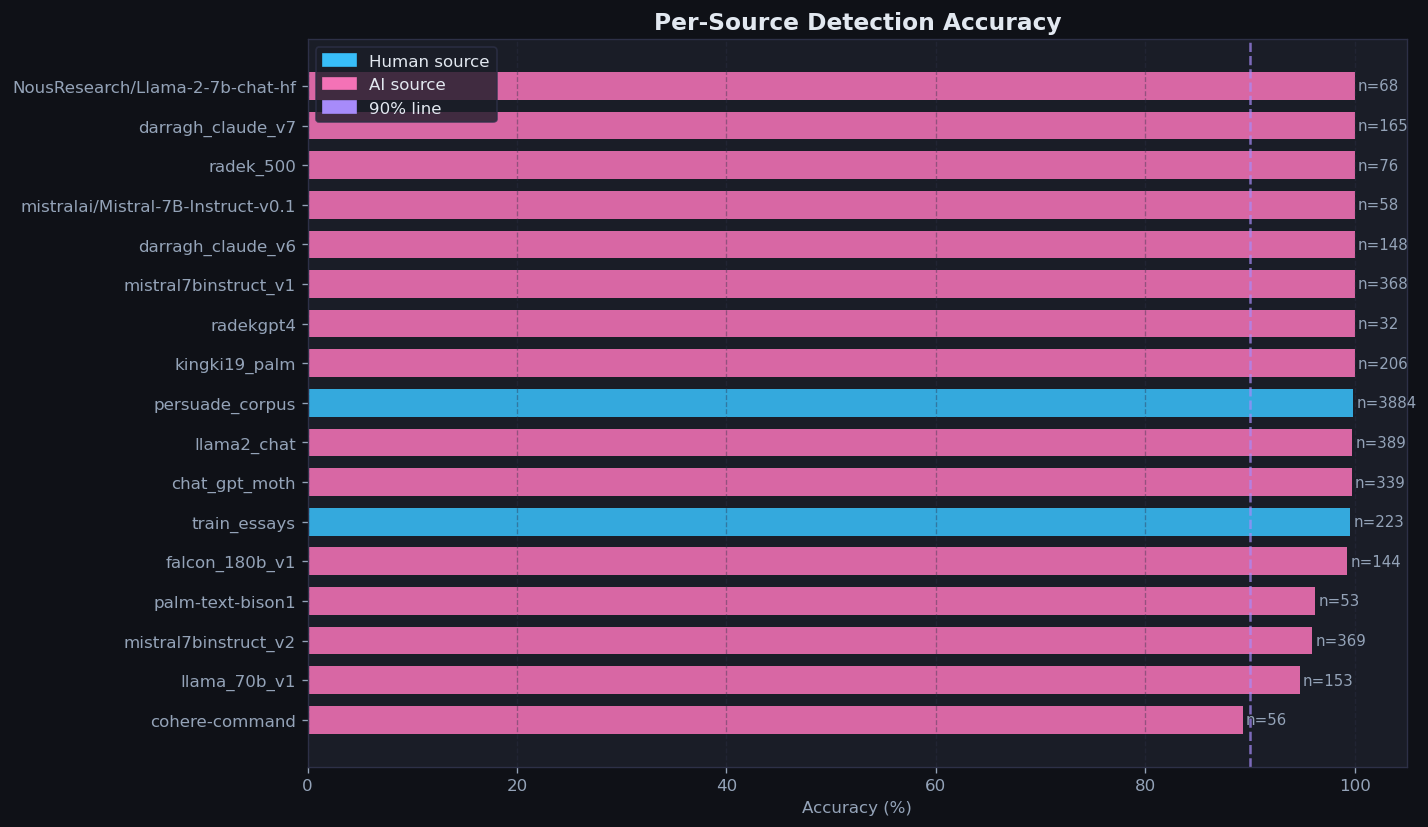

In [6]:
df_val = df_val.copy()
df_val['pred_prob'] = ens_probs
df_val['pred']      = ens_preds
df_val['correct']   = (df_val['pred'] == df_val['label']).astype(int)

source_perf = df_val.groupby('source').agg(
    count=('label','count'),
    accuracy=('correct','mean'),
    ai_prob_mean=('pred_prob','mean')
).sort_values('accuracy', ascending=True).reset_index()

display(source_perf.round(4))

fig, ax = plt.subplots(figsize=(12, 7))
colors = [HUMAN_COLOR if ('persuade' in s or 'train_essays' in s) else AI_COLOR for s in source_perf['source']]
bars = ax.barh(source_perf['source'], source_perf['accuracy']*100, color=colors, alpha=0.88, edgecolor='none', height=0.7)
ax.axvline(90, color=ACCENT, linestyle='--', alpha=0.7, label='90% line')
for bar, count in zip(bars, source_perf['count']):
    ax.text(bar.get_width()+0.3, bar.get_y()+bar.get_height()/2,
            f'n={count}', va='center', fontsize=9, color='#94A3B8')
human_p = mpatches.Patch(color=HUMAN_COLOR, label='Human source')
ai_p    = mpatches.Patch(color=AI_COLOR,    label='AI source')
ax.legend(handles=[human_p, ai_p, mpatches.Patch(color=ACCENT, label='90% line')],
          facecolor='#1A1D27', edgecolor='#2D3047')
ax.set_title('Per-Source Detection Accuracy', fontsize=14, fontweight='bold', color='#E2E8F0')
ax.set_xlabel('Accuracy (%)', color='#94A3B8'); ax.grid(axis='x'); ax.set_xlim(0, 105)
plt.tight_layout()
plt.savefig('../models/eval_per_source.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 5. Error Analysis — Hardest Examples

In [7]:
# False Positives (Human labelled as AI)
fp = df_val[(df_val.label==0) & (df_val.pred==1)].nlargest(5, 'pred_prob')
print(f'=== False Positives (Human predicted as AI): {len(df_val[(df_val.label==0)&(df_val.pred==1)])} ===')
for _, row in fp.iterrows():
    print(f'\n[Source: {row["source"]} | Pred prob: {row["pred_prob"]:.3f}]')
    print(row['text'][:300] + '...')
    print('-'*60)

=== False Positives (Human predicted as AI): 5 ===

[Source: persuade_corpus | Pred prob: 0.816]
Participating in extracurricular activity like, sports or any clubs is good for any student so they can make new friends or learn new activity's. Activity's can boost your health, social skills, and interest on a activity. For example students could play soccer and basketball or join a art club.

Pl...
------------------------------------------------------------

[Source: persuade_corpus | Pred prob: 0.716]
participating in extracurricular activities is like going on your dream vacation, it's fun and enjoyable. i agree with the principal, students should participate in extracurricular activities, for it helps students build social skills, allows students to build friendships, and teaches students how t...
------------------------------------------------------------

[Source: persuade_corpus | Pred prob: 0.571]
It is hypothesized that despite an effective way of communication, using cell pho

In [8]:
# False Negatives (AI labelled as Human)
fn = df_val[(df_val.label==1) & (df_val.pred==0)].nsmallest(5, 'pred_prob')
print(f'=== False Negatives (AI predicted as Human): {len(df_val[(df_val.label==1)&(df_val.pred==0)])} ===')
for _, row in fn.iterrows():
    print(f'\n[Source: {row["source"]} | Pred prob: {row["pred_prob"]:.3f}]')
    print(row['text'][:300] + '...')
    print('-'*60)

=== False Negatives (AI predicted as Human): 35 ===

[Source: mistral7binstruct_v2 | Pred prob: 0.005]
 Have you ever thought about asking other people for advice? Perhaps, people sometimes talk to more than one person because they will be able to know which is the best choice to go with, to find their next step, and that person will stop thinking about their choice too much.

Firstly, the person wil...
------------------------------------------------------------

[Source: mistral7binstruct_v2 | Pred prob: 0.007]
 Dear Principal

I believe that we should have policy number one. All students should be able to use their phones during their free time and lunch. It is better to have them off in class time. If we do not allow this, students will not learn. They should be turned off or kept low. Some students woul...
------------------------------------------------------------

[Source: mistral7binstruct_v2 | Pred prob: 0.021]
 In the words of Ralph Waldo Emerson, "To be yourself in a world 

## 6. Sentence-Level Attribution Heatmap (Explainability)

In [9]:
def sentence_ai_scores(text, tfidf_char, tfidf_word, sgd_clf, lgb_model, w_sgd, w_lgb, threshold):
    """Score each sentence in a text for AI probability."""
    text_clean = preprocess_text(text)
    sentences  = [s.strip() for s in re.split(r'(?<=[.!?])\s+', text_clean) if len(s.strip()) > 10]
    if not sentences:
        return [], []
    
    X_char = tfidf_char.transform(sentences)
    X_word = tfidf_word.transform(sentences)
    X_ling = linguistic_features(sentences)
    X_all  = hstack([X_char, X_word, csr_matrix(X_ling)])
    
    s_probs = w_sgd*sgd_clf.predict_proba(X_all)[:,1] + w_lgb*lgb_model.predict_proba(X_all)[:,1]
    return sentences, s_probs.tolist()

# Demo on a sample AI text
sample_ai = df_val[df_val.label==1].iloc[0]['text']
sents, scores = sentence_ai_scores(sample_ai, tfidf_char, tfidf_word, sgd_clf, lgb_model, w_sgd, w_lgb, THRESHOLD)

print('Sample AI text — per-sentence AI probability:')
print('='*60)
for sent, score in zip(sents[:10], scores[:10]):
    bar = '█' * int(score * 20)
    label_tag = '🤖 AI' if score >= THRESHOLD else '👤 HUM'
    print(f'{label_tag} [{score:.2f}] {bar}')
    print(f'         {sent[:80]}...')
    print()

Sample AI text — per-sentence AI probability:
🤖 AI [0.97] ███████████████████
         dear state senator, 

as a constituent, i urge you to consider the importance of...

🤖 AI [0.97] ███████████████████
         although some argue that a direct popular vote is more democratic, i believe the...

🤖 AI [0.91] ██████████████████
         firstly, the electoral college provides a level of certainty in the election out...

🤖 AI [0.98] ███████████████████
         unlike a popular vote, where a candidate could win with a plurality of votes, th...

🤖 AI [0.95] ███████████████████
         this ensures that the winner has broad support across the country, rather than s...

🤖 AI [0.97] ███████████████████
         a related point is that the electoral college encourages candidates to campaign ...

🤖 AI [0.94] ██████████████████
         this leads to a more diverse and well-rounded campaign, where candidates must ap...

🤖 AI [0.98] ███████████████████
         in contrast, a direct popular vot

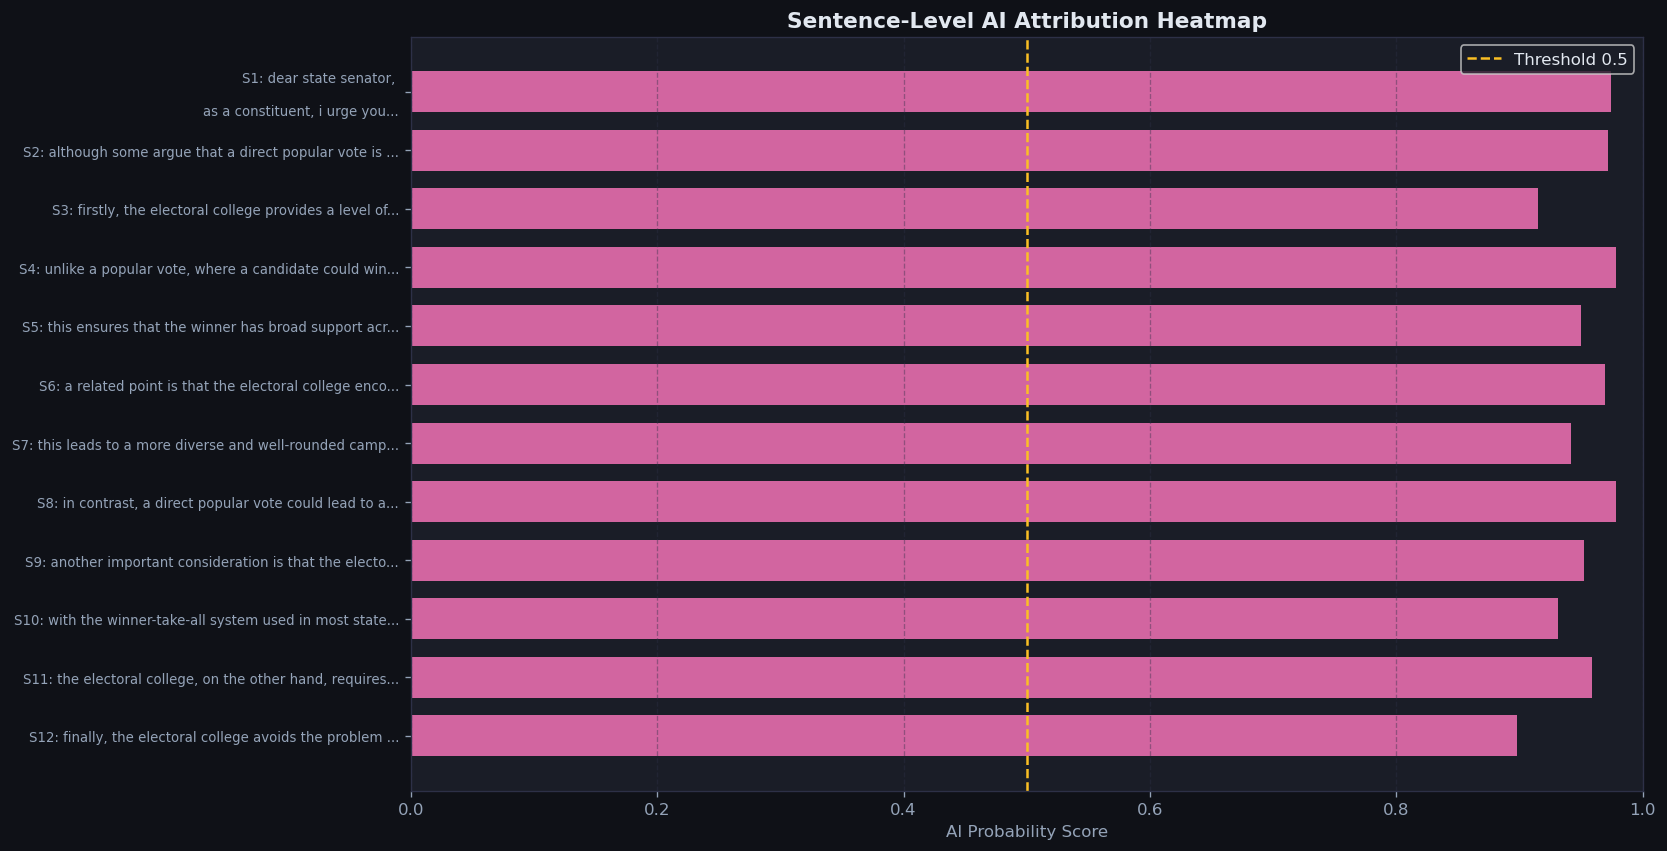

In [10]:
# Visual heatmap of sentence scores
if sents and scores:
    disp_sents  = sents[:12]
    disp_scores = scores[:12]
    
    fig, ax = plt.subplots(figsize=(14, max(4, len(disp_sents)*0.6)))
    colors = [AI_COLOR if s >= THRESHOLD else HUMAN_COLOR for s in disp_scores]
    bars = ax.barh(range(len(disp_sents)), disp_scores, color=colors, edgecolor='none', alpha=0.85, height=0.7)
    ax.axvline(THRESHOLD, color='#FBBF24', linestyle='--', label=f'Threshold {THRESHOLD}')
    ax.set_yticks(range(len(disp_sents)))
    ax.set_yticklabels([f'S{i+1}: {s[:50]}...' for i,s in enumerate(disp_sents)], fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_xlabel('AI Probability Score', color='#94A3B8')
    ax.set_title('Sentence-Level AI Attribution Heatmap', fontsize=13, fontweight='bold', color='#E2E8F0')
    ax.invert_yaxis(); ax.legend(facecolor='#1A1D27'); ax.grid(axis='x')
    plt.tight_layout()
    plt.savefig('../models/eval_sentence_heatmap.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
    plt.show()

## 7. Final Performance Card

In [11]:
prec = precision_score(y_val, ens_preds)
rec  = recall_score(y_val, ens_preds)
f1   = f1_score(y_val, ens_preds)
acc  = accuracy_score(y_val, ens_preds)
auc  = roc_auc_score(y_val, ens_probs)

print('┌─────────────────────────────────────────────────┐')
print('│         AuthentiQ Ensemble Model v1.0           │')
print('│         AI Text Detection Performance Card      │')
print('├─────────────────────────────────────────────────┤')
print(f'│  ROC-AUC:   {auc:.4f}   ({"🟢 Excellent" if auc>0.95 else "🟡 Good" if auc>0.90 else "🔴 Fair"})    │')
print(f'│  Accuracy:  {acc:.4f}                              │')
print(f'│  F1-Score:  {f1:.4f}                              │')
print(f'│  Precision: {prec:.4f}                              │')
print(f'│  Recall:    {rec:.4f}                              │')
print(f'│  Threshold: {THRESHOLD}                               │')
print(f'│  Val size:  {len(y_val):,} samples                       │')
print('├─────────────────────────────────────────────────┤')
print(f'│  Models: SGDClassifier + LightGBM (ensemble)   │')
print(f'│  Features: Char TF-IDF + Word TF-IDF + Ling    │')
print(f'│  Dataset: train_v2_drcat_02 (44,868 samples)   │')
print('└─────────────────────────────────────────────────┘')

┌─────────────────────────────────────────────────┐
│         AuthentiQ Ensemble Model v1.0           │
│         AI Text Detection Performance Card      │
├─────────────────────────────────────────────────┤
│  ROC-AUC:   0.9970   (🟢 Excellent)    │
│  Accuracy:  0.9941                              │
│  F1-Score:  0.9923                              │
│  Precision: 0.9981                              │
│  Recall:    0.9867                              │
│  Threshold: 0.5                               │
│  Val size:  6,731 samples                       │
├─────────────────────────────────────────────────┤
│  Models: SGDClassifier + LightGBM (ensemble)   │
│  Features: Char TF-IDF + Word TF-IDF + Ling    │
│  Dataset: train_v2_drcat_02 (44,868 samples)   │
└─────────────────────────────────────────────────┘


## ✅ Evaluation Complete

**Artifacts saved in `../models/`:**
- `tfidf_char.pkl` — Character n-gram TF-IDF vectorizer
- `tfidf_word.pkl` — Word n-gram TF-IDF vectorizer  
- `sgd_classifier.pkl` — Calibrated SGD classifier
- `lgb_classifier.pkl` — LightGBM classifier
- `model_meta.json` — Metadata & performance metrics
- `eval_roc_pr.png`, `eval_confusion_matrix.png`, `eval_per_source.png`, `eval_sentence_heatmap.png`

**→ Next: `04_inference_integration.ipynb`** to wire the model into the FastAPI backend